# Power-Stress-3 data pipeline
In this notebook we analyze the results from run1, run2, run3 and run4

the CPU settings were 30 CPUs per pod, and 30 CPU workers per pod

In [1]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
from analysis_functions import get_time_periods, get_power_data, divide_power_data_into_step_periods, compute_relative_energy_usage
from analysis_functions import plot_energy_usage, plot_multiple_datasets, plot_energy_usage_overlay_multiple_datasets

In [3]:
base_path = "../../data/power-stress-3"
corresponding_datasets = {
    "run1": {
        "simpipe": f"{base_path}/run1.dat", 
        "tapo": f'{base_path}/power-run2.xls',
        "start_time_baseline": '2026-10-25T09:00:00', 
        "end_time_baseline": '2026-10-25T14:30:00',
        "start_time_pipeline": '2026-10-25T14:41:18',
        "end_time_pipeline": '2026-10-25T17:41:32'},
    "run2": {
        "simpipe": f"{base_path}/run2.dat", 
        "tapo": f'{base_path}/power-run2.xls',
        "start_time_baseline": '2026-10-25T22:00:00', 
        "end_time_baseline": '2026-10-26T07:30:00',
        "start_time_pipeline": '2026-10-25T18:28:14',
        "end_time_pipeline": '2026-10-25T21:28:27'},
    "run3": {
        "simpipe": f"{base_path}/run3.dat", 
        "tapo": f'{base_path}/power-run3.xls',
        "start_time_baseline": '2026-10-25T22:00:00', 
        "end_time_baseline": '2026-10-26T08:00:00',
        "start_time_pipeline": '2026-10-26T08:32:31',
        "end_time_pipeline": '2026-10-26T11:32:45'},
    "run4": {
        "simpipe": f"{base_path}/run4.dat", 
        "tapo": f'{base_path}/power-run4.xls',
        "start_time_baseline": '2026-10-26T16:00:00',
        "end_time_baseline": '2026-10-27T07:00:00',
        "start_time_pipeline": '2026-10-26T12:37:43',
        "end_time_pipeline": '2026-10-26T15:37:59'}
}

In [8]:
# runNr = 1, 2, 3, 4 // corresponds to 0, 1, 2, 3 in the corresponding_datasets
runNr = "run3"
path = corresponding_datasets[runNr]["simpipe"]
carbontracker_simpipe_data = pd.read_csv(path, comment='#', header=0, sep=r'\s+')
power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo"]) # get tapo power data
#power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo-filtered"]) # get tapo power data
power_data.describe()

,Date,Power(W),Energy(kWh)
count,287,287.000000,287.000000
mean,2026-10-25 23:55:00,293.121951,0.024427
min,2026-10-25 12:00:00,198.000000,0.016500
25%,2026-10-25 17:57:30,204.000000,0.017000
50%,2026-10-25 23:55:00,209.000000,0.017417
75%,2026-10-26 05:52:30,437.000000,0.036417
max,2026-10-26 11:50:00,447.000000,0.037250
std,NaN,113.153907,0.009429


In [9]:
carbontracker_simpipe_data

,step,start,stop,duration,co2,energy,status
0,power-stress(0:0),2026-10-26T07:32:31Z,2026-10-26T10:32:45Z,10814,96.329,3.202405,Error


In [10]:
dt_format = '%Y-%m-%d %H:%M:%S'
for _, row in carbontracker_simpipe_data.iterrows():
    start_time = pd.to_datetime(row['start']).strftime(dt_format)
    stop_time = pd.to_datetime(row['stop']).strftime(dt_format)
    print(f"Step: {row['step']}, Start: {start_time}, Stop: {stop_time}")

Step: power-stress(0:0), Start: 2026-10-26 07:32:31, Stop: 2026-10-26 10:32:45


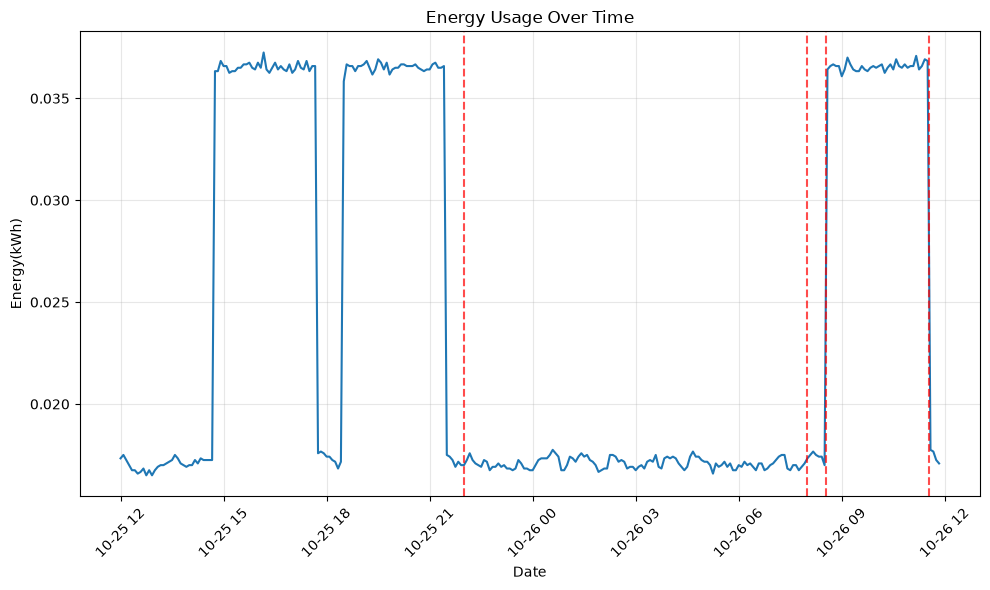

In [11]:
#raw_power_data.plot(x='Date', y='Energy(kWh)', title='Energy Usage Over Time')
#start_time = corresponding_datasets[runNr -1][2]
title = "Energy Usage Over Time"
xcol="Date"
ycol="Energy(kWh)"
start_time_baseline = corresponding_datasets[runNr]["start_time_baseline"]
end_time_baseline = corresponding_datasets[runNr]["end_time_baseline"]
start_time_pipeline = corresponding_datasets[runNr]["start_time_pipeline"]
end_time_pipeline = corresponding_datasets[runNr]["end_time_pipeline"]

timestamps = [start_time_baseline, end_time_baseline, start_time_pipeline, end_time_pipeline]

plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=None, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=end_time_pipeline, timestamps=timestamps)


In [14]:
time_periods = get_time_periods(carbontracker_simpipe_data, start_time_baseline, end_time_baseline)

    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2026-10-25T09:00:00 to 2026-10-25T14:30:00
      - power-stress(0:0): 2026-10-25 13:41:18 to 2026-10-25 16:41:32


In [15]:
time_periods

[('baseline', '2026-10-25T09:00:00', '2026-10-25T14:30:00'),
 ('power-stress(0:0)', '2026-10-25 13:41:18', '2026-10-25 16:41:32')]